In [1]:
%pip install pandas numpy scikit-learn matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Works whether the notebook starts in the repo root or pbl3
if Path("training_image_features.csv").exists():
    DATA_DIR = Path(".")
else:
    DATA_DIR = Path("..")

train_df = pd.read_csv(DATA_DIR / "training_image_features.csv")
val_df = pd.read_csv(DATA_DIR / "validation_image_features.csv")
test_df = pd.read_csv(DATA_DIR / "testing_image_features.csv")

TARGET = "Condition_Class"
GATE_TARGET = "Material_Type"

excluded = [
    TARGET, GATE_TARGET, "Sample_ID", "Image_ID",
    "Damage_Score", "Condition_Score", "Structural_Integrity",
    "Recovery_Pathway", "Reconditioning_Required",
    "Recovery_Potential", "Alternative_Use_Category",
    "Alternative_Use_Suitability", "pixel_img_width",
    "pixel_img_height"
]

if TARGET not in train_df.columns or GATE_TARGET not in train_df.columns:
    raise ValueError("Training data must contain Condition_Class and Material_Type.")

feature_cols = [c for c in train_df.columns if c not in excluded]

X_train = train_df[feature_cols].copy()
y_train = train_df[TARGET].copy()
gate_train = train_df[GATE_TARGET].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df[TARGET].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df[TARGET].copy()

# Ensure validation and test use the same columns and order
X_val = X_val.reindex(columns=feature_cols)
X_test = X_test.reindex(columns=feature_cols)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in feature_cols if c not in numeric_cols]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
])

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)
print("Condition classes:", sorted(y_train.astype(str).unique()))
print("Material types:", sorted(gate_train.dropna().astype(str).unique()))

Training shape: (10058, 29)
Validation shape: (3237, 29)
Test shape: (3224, 29)
Condition classes: ['Excellent', 'Fair', 'Good', 'Poor']
Material types: ['brick', 'concrete', 'foam', 'general_w', 'gypsum_board', 'pipes', 'plastic', 'stone', 'tile', 'wood']


In [3]:
class MixtureOfExperts:
    def __init__(self, preprocessor, min_samples=30, random_state=42):
        self.preprocessor = preprocessor
        self.min_samples = min_samples
        self.random_state = random_state
        self.gate = None
        self.experts = {}
        self.classes_ = None

    def fit(self, X, y, material):
        material = material.fillna("Unknown").astype(str)

        self.classes_ = np.unique(y)
        self.gate = Pipeline([
            ("prep", clone(self.preprocessor)),
            ("model", LogisticRegression(max_iter=1500, class_weight="balanced"))
        ])
        self.gate.fit(X, material)

        self.experts = {}
        for material_type in material.unique():
            mask = material == material_type

            if mask.sum() < self.min_samples:
                continue

            if y[mask].nunique() < 2:
                continue

            expert = Pipeline([
                ("prep", clone(self.preprocessor)),
                ("model", RandomForestClassifier(
                    n_estimators=150,
                    max_depth=15,
                    min_samples_leaf=2,
                    class_weight="balanced",
                    random_state=self.random_state,
                    n_jobs=-1
                ))
            ])

            expert.fit(X.loc[mask], y.loc[mask])
            self.experts[material_type] = expert

        if not self.experts:
            raise ValueError("No expert models were trained. Check material groups and min_samples.")

        return self

    def predict_proba(self, X):
        gate_probs = self.gate.predict_proba(X)
        gate_classes = self.gate.named_steps["model"].classes_

        final_probs = np.zeros((len(X), len(self.classes_)))

        for j, material_type in enumerate(gate_classes):
            expert = self.experts.get(material_type)

            if expert is None:
                continue

            expert_probs = expert.predict_proba(X)
            expert_classes = expert.named_steps["model"].classes_

            for k, label in enumerate(expert_classes):
                class_index = np.where(self.classes_ == label)[0][0]
                final_probs[:, class_index] += gate_probs[:, j] * expert_probs[:, k]

        row_sums = final_probs.sum(axis=1, keepdims=True)
        final_probs = np.divide(
            final_probs, row_sums,
            out=np.zeros_like(final_probs),
            where=row_sums != 0
        )

        # Fallback if a row received no probability from a trained expert
        missing = row_sums.ravel() == 0
        if missing.any():
            fallback = np.bincount(
                LabelEncoder().fit_transform(y_train),
                minlength=len(self.classes_)
            ).astype(float)
            fallback /= fallback.sum()
            final_probs[missing] = fallback

        return final_probs

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


# Train using training data only
moe_model = MixtureOfExperts(preprocessor, min_samples=30)
moe_model.fit(X_train, y_train, gate_train)

print("Trained experts:", list(moe_model.experts.keys()))

Trained experts: ['brick', 'concrete', 'tile', 'foam', 'general_w', 'pipes', 'plastic', 'gypsum_board', 'wood', 'stone']


In [4]:
val_pred = moe_model.predict(X_val)

val_accuracy = accuracy_score(y_val, val_pred)
val_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)

print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Macro F1:", round(val_f1, 4))
print(classification_report(y_val, val_pred, zero_division=0))

Validation Accuracy: 0.9305
Validation Macro F1: 0.8854
              precision    recall  f1-score   support

   Excellent       0.97      0.70      0.81        40
        Fair       0.96      0.94      0.95      2183
        Good       0.85      0.95      0.90       722
        Poor       0.92      0.85      0.88       292

    accuracy                           0.93      3237
   macro avg       0.92      0.86      0.89      3237
weighted avg       0.93      0.93      0.93      3237



In [5]:
X_train_full = pd.concat([X_train, X_val], ignore_index=True)
y_train_full = pd.concat([y_train, y_val], ignore_index=True)

gate_full = pd.concat([
    gate_train,
    train_df[GATE_TARGET].fillna("Unknown")
    if GATE_TARGET in train_df.columns else gate_train
], ignore_index=True)

# Add the validation material labels
gate_full = pd.concat([
    train_df[GATE_TARGET].fillna("Unknown"),
    val_df[GATE_TARGET].fillna("Unknown")
], ignore_index=True)

final_moe = MixtureOfExperts(preprocessor, min_samples=30)
final_moe.fit(X_train_full, y_train_full, gate_full)

test_pred = final_moe.predict(X_test)

test_accuracy = accuracy_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred, average="macro", zero_division=0)

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro F1:", round(test_f1, 4))
print(classification_report(y_test, test_pred, zero_division=0))

Test Accuracy: 0.9467
Test Macro F1: 0.9324
              precision    recall  f1-score   support

   Excellent       0.95      0.90      0.93        41
        Fair       0.98      0.94      0.96      2193
        Good       0.87      0.96      0.91       716
        Poor       0.93      0.93      0.93       274

    accuracy                           0.95      3224
   macro avg       0.93      0.94      0.93      3224
weighted avg       0.95      0.95      0.95      3224



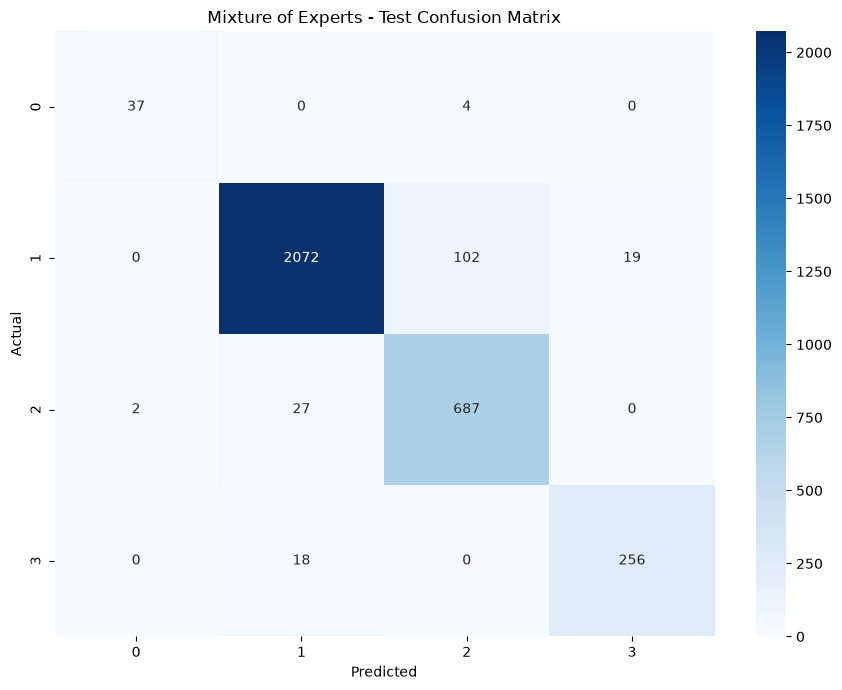

                Model       Split  Accuracy  Macro F1
0  Mixture of Experts  Validation  0.930491  0.885369
1  Mixture of Experts        Test  0.946650  0.932407
Saved metrics and model.


In [6]:
os.makedirs("model_results", exist_ok=True)
os.makedirs("saved_models", exist_ok=True)

moe_metrics = pd.DataFrame([
    {
        "Model": "Mixture of Experts",
        "Split": "Validation",
        "Accuracy": val_accuracy,
        "Macro F1": val_f1
    },
    {
        "Model": "Mixture of Experts",
        "Split": "Test",
        "Accuracy": test_accuracy,
        "Macro F1": test_f1
    }
])

moe_metrics.to_csv("model_results/mixture_of_experts_metrics.csv", index=False)
joblib.dump(final_moe, "saved_models/mixture_of_experts.joblib")

cm = confusion_matrix(y_test, test_pred, labels=final_moe.classes_)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Mixture of Experts - Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(moe_metrics)
print("Saved metrics and model.")